# Tugas - Klasifikasi dengan Decision Tree

| Nama | NRP |
|------|-----|
| Sulaiman Faiz Tsaqib | 5054251048 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model Decision Tree Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja Decision Tree secara praktik, khususnya:
1. Perbedaan hasil antara kriteria split Gini Impurity dan Entropy
2. Pengaruh regularisasi (max_depth) terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Decision Tree dengan kriteria Gini dan Entropy.
   - Lakukan eksperimen regularisasi dengan variasi nilai max_depth.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('bankruptcy.csv')
df.columns = df.columns.str.strip()
print(df.shape)
df.info()
display(df.describe().T)
print('Total missing value:', df.isna().sum().sum())

(6819, 96)
<class 'pandas.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Bankrupt?                                                6819 non-null   int64  
 1   ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2   ROA(A) before interest and % after tax                   6819 non-null   float64
 3   ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4   Operating Gross Margin                                   6819 non-null   float64
 5   Realized Sales Gross Margin                              6819 non-null   float64
 6   Operating Profit Rate                                    6819 non-null   float64
 7   Pre-tax net Interest Rate                                6819 non-null   float64
 8   After-tax net Interest Rate 

,count,mean,std,min,25%,50%,75%,max
Bankrupt?,6819.0,0.032263,0.176710,0.0,0.000000,0.000000,0.000000,1.0
ROA(C) before interest and depreciation before interest,6819.0,0.505180,0.060686,0.0,0.476527,0.502706,0.535563,1.0
ROA(A) before interest and % after tax,6819.0,0.558625,0.065620,0.0,0.535543,0.559802,0.589157,1.0
ROA(B) before interest and depreciation after tax,6819.0,0.553589,0.061595,0.0,0.527277,0.552278,0.584105,1.0
Operating Gross Margin,6819.0,0.607948,0.016934,0.0,0.600445,0.605997,0.613914,1.0
...,...,...,...,...,...,...,...,...
Liability to Equity,6819.0,0.280365,0.014463,0.0,0.276944,0.278778,0.281449,1.0
Degree of Financial Leverage (DFL),6819.0,0.027541,0.015668,0.0,0.026791,0.026808,0.026913,1.0
Interest Coverage Ratio (Interest expense to EBIT),6819.0,0.565358,0.013214,0.0,0.565158,0.565252,0.565725,1.0
Net Income Flag,6819.0,1.000000,0.000000,1.0,1.000000,1.000000,1.000000,1.0


Total missing value: 0


Bankrupt?
0    0.967737
1    0.032263
Name: proportion, dtype: float64


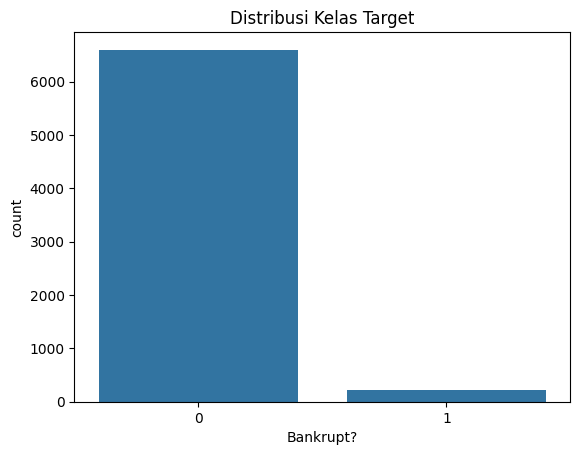

In [3]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
target = 'Bankrupt?'
print(df[target].value_counts(normalize=True))
sns.countplot(x=target, data=df)
plt.title('Distribusi Kelas Target')
plt.show()

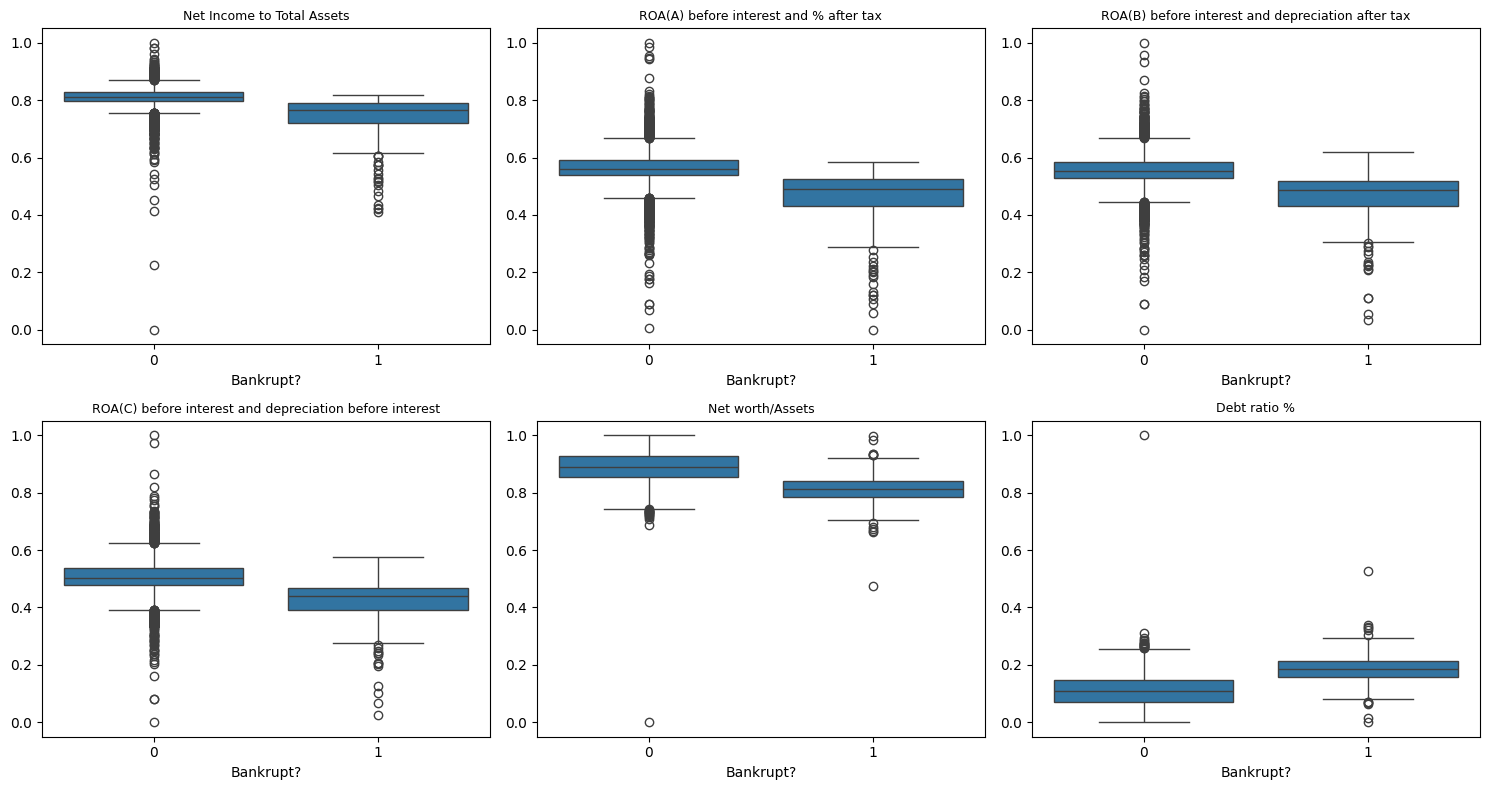

In [4]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas antar kelas.
top = df.corr()[target].drop(target).abs().nlargest(6).index
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, top):
    sns.boxplot(x=target, y=col, data=df, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

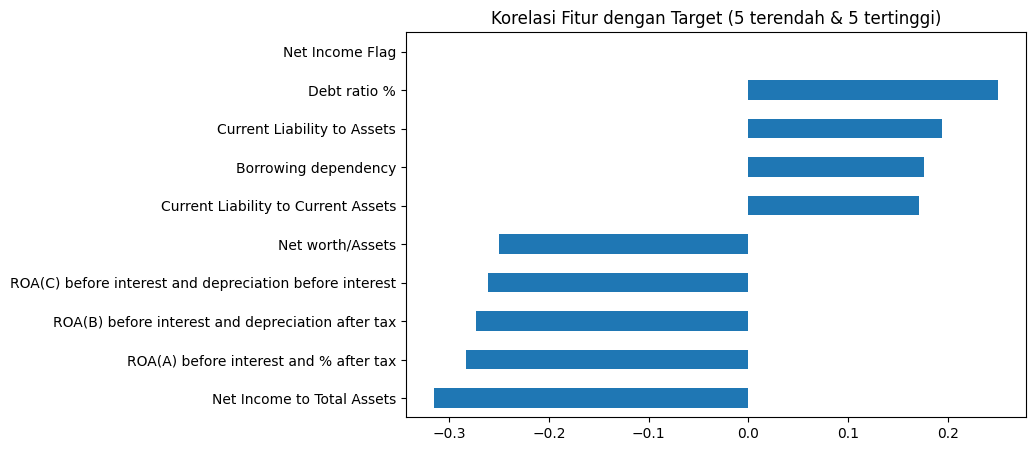

In [5]:
corr = df.corr()[target].drop(target).sort_values()
pd.concat([corr.head(5), corr.tail(5)]).plot.barh(figsize=(8, 5))
plt.title('Korelasi Fitur dengan Target (5 terendah & 5 tertinggi)')
plt.show()

# 2. Preprocessing

In [6]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
# Dataset tidak memiliki missing value, sehingga tidak perlu imputasi.
print(df.isna().sum().sum())

0


In [7]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
# Catatan: Decision Tree secara konsep bisa menangani fitur kategorikal secara langsung tanpa One-Hot Encoding,
# tetapi implementasi DecisionTreeClassifier pada scikit-learn tetap mengharuskan input berupa angka.
# Semua fitur sudah numerik, sehingga tidak perlu encoding.
print(df.select_dtypes(exclude='number').columns.tolist())

[]


In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X = df.drop(columns=target)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(5455, 95) (1364, 95)


**Catatan penting:** Decision Tree tidak memerlukan feature scaling (StandardScaler/MinMaxScaler). Split pada Decision Tree dilakukan berdasarkan threshold per fitur satu per satu, bukan berdasarkan jarak antar titik seperti pada KNN atau SVM. Jadi kalian tidak perlu melakukan scaling pada tahap ini.

# 3. Eksperimen Model

## 3.1 Decision Tree dengan Kriteria Gini

Gini Impurity adalah kriteria default pada DecisionTreeClassifier di scikit-learn. Kriteria ini mengukur peluang kesalahan klasifikasi jika sebuah sampel dipilih secara acak dari suatu node.

In [9]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='gini' menggunakan train set.
gini = DecisionTreeClassifier(criterion='gini', random_state=42).fit(X_train, y_train)

In [10]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_gini = gini.predict(X_test)

## 3.2 Decision Tree dengan Kriteria Entropy

Entropy (Information Gain) adalah kriteria alternatif yang mengukur tingkat ketidakpastian distribusi kelas pada suatu node.

In [11]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='entropy' menggunakan train set.
# Gunakan nilai hyperparameter lain yang sama seperti model Gini di atas, agar perbandingan adil.
entropy = DecisionTreeClassifier(criterion='entropy', random_state=42).fit(X_train, y_train)

In [12]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_entropy = entropy.predict(X_test)

## 3.3 Eksperimen Regularisasi: Pengaruh max_depth terhadap Overfitting

Decision Tree yang dibiarkan tumbuh tanpa batas cenderung overfitting terhadap data training. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai max_depth memengaruhi akurasi training dan testing.

In [13]:
# Latih beberapa model DecisionTreeClassifier dengan variasi nilai max_depth,
# misalnya 1, 2, 3, 5, 10, dan None (tanpa batas kedalaman).
# Gunakan kriteria split terbaik dari salah satu percobaan sebelumnya (Gini atau Entropy).
depths = [1, 2, 3, 5, 10, None]
models = {d: DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42).fit(X_train, y_train) for d in depths}

In [14]:
# Hitung akurasi pada train set dan test set untuk setiap nilai max_depth yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
train_acc = [accuracy_score(y_train, m.predict(X_train)) for m in models.values()]
test_acc = [accuracy_score(y_test, m.predict(X_test)) for m in models.values()]
display(pd.DataFrame({'max_depth': [str(d) for d in depths], 'train_acc': train_acc, 'test_acc': test_acc}))

,max_depth,train_acc,test_acc
0,1,0.967736,0.967742
1,2,0.967736,0.967742
2,3,0.968286,0.969941
3,5,0.974335,0.966276
4,10,0.993034,0.963343
5,None,1.000000,0.964076


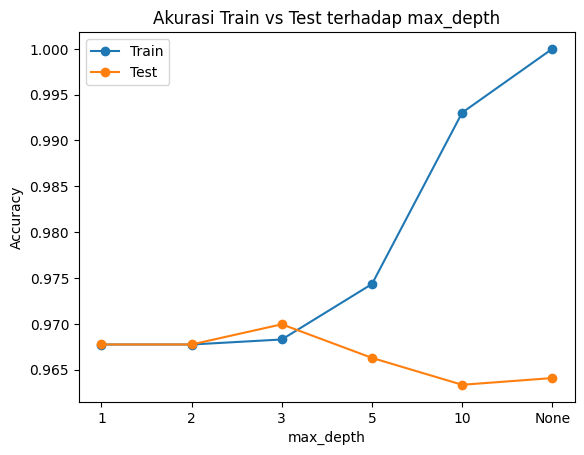

In [15]:
# Plot grafik akurasi training vs testing terhadap max_depth dalam satu chart.
# Amati pada titik berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).
labels = [str(d) for d in depths]
plt.plot(labels, train_acc, marker='o', label='Train')
plt.plot(labels, test_acc, marker='o', label='Test')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Akurasi Train vs Test terhadap max_depth')
plt.legend()
plt.show()

# 4. Evaluasi Model

In [16]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model Gini dan Entropy.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
preds = {'Gini': y_pred_gini, 'Entropy': y_pred_entropy}
pd.DataFrame({name: [accuracy_score(y_test, p), precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)]
              for name, p in preds.items()}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score'])

,Gini,Entropy
Accuracy,0.961144,0.964076
Precision,0.400000,0.435897
Recall,0.409091,0.386364
F1-Score,0.404494,0.409639


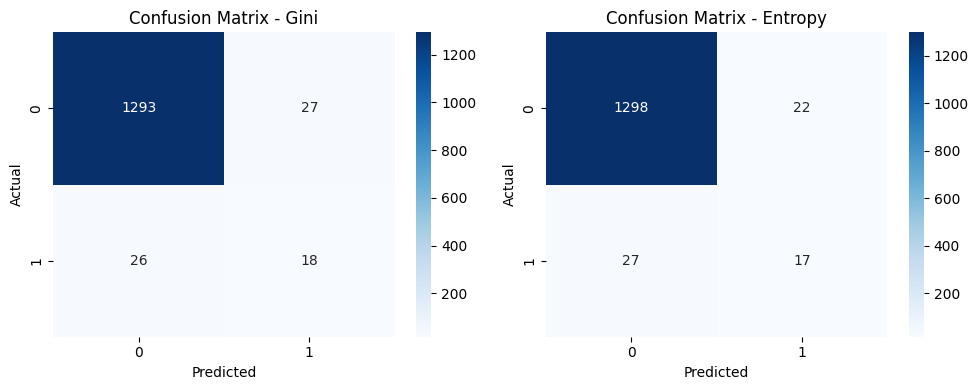

In [17]:
# Tampilkan Confusion Matrix untuk model Gini dan Entropy dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, p) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

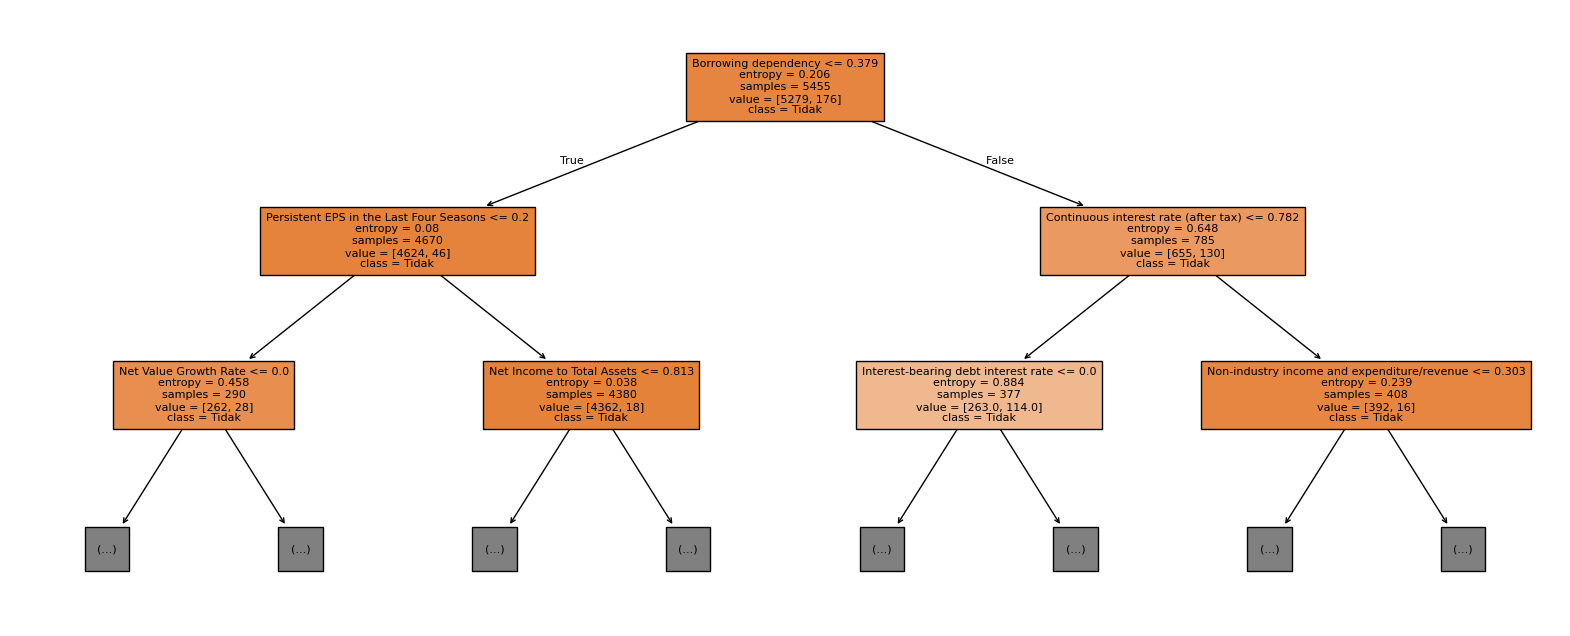

In [18]:
# Visualisasikan struktur Decision Tree (gunakan plot_tree) untuk model dengan performa terbaik.
# Batasi kedalaman visualisasi (misalnya max_depth=2 atau 3 pada parameter plot_tree) agar tetap mudah dibaca.
best = entropy if f1_score(y_test, y_pred_entropy) >= f1_score(y_test, y_pred_gini) else gini
plt.figure(figsize=(20, 8))
plot_tree(best, max_depth=2, feature_names=X.columns, class_names=['Tidak', 'Bangkrut'], filled=True, fontsize=8)
plt.show()

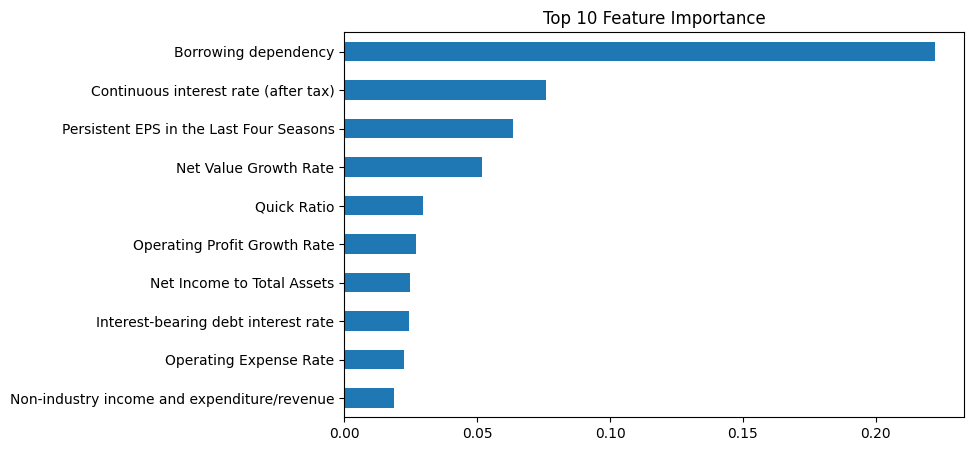

In [19]:
# Tampilkan feature importance dari model terbaik dalam bentuk bar chart horizontal.
# Urutkan dari fitur yang paling berpengaruh.
imp = pd.Series(best.feature_importances_, index=X.columns).nlargest(10).sort_values()
imp.plot.barh(figsize=(8, 5))
plt.title('Top 10 Feature Importance')
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa Decision Tree dengan kriteria Gini vs Entropy. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (max_depth). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Fitur apa yang paling berpengaruh terhadap prediksi model, berdasarkan feature importance?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

**Jawaban:**

- **Gini vs Entropy:** Hasil keduanya mirip. Entropy sedikit lebih baik pada Accuracy (0.964 vs 0.961), Precision (0.436 vs 0.400), dan F1 (0.410 vs 0.404), sedangkan Gini sedikit unggul pada Recall (0.409 vs 0.386). Dari 44 perusahaan bangkrut di test set, Gini menangkap 18 dan Entropy 17. Perbedaannya tidak signifikan karena kedua kriteria sama-sama mengukur impurity dan biasanya memilih split yang hampir sama. Selisih kecil muncul karena pohon tumbuh tanpa batas (kedalaman 20 untuk Gini, 17 untuk Entropy), sehingga perbedaan split kecil di node bawah ikut berpengaruh.
- **Regularisasi max_depth:** Pada max_depth 1–2 model hanya menebak kelas mayoritas (akurasi 0.9677, sama dengan proporsi kelas 0). Akurasi test tertinggi ada di max_depth=3 (0.970). Mulai max_depth=5 model menunjukkan gejala overfitting: akurasi train terus naik (0.974 → 0.993 → 1.000), sedangkan akurasi test turun (0.966 → 0.963 → 0.964). Celah antara kurva train dan test makin lebar seiring bertambahnya kedalaman.
- **Feature importance:** Pada model terbaik (Entropy), fitur paling berpengaruh adalah *Borrowing dependency* (0.222), diikuti *Continuous interest rate (after tax)* dan *Persistent EPS in the Last Four Seasons*. Artinya ketergantungan pada utang dan kemampuan menghasilkan laba menjadi indikator utama kebangkrutan.
- **Catatan:** Dataset sangat imbalanced (96.8% vs 3.2%), sehingga accuracy kurang representatif. Recall dan F1 kelas bangkrut (~0.4) menunjukkan model masih kesulitan mendeteksi perusahaan bangkrut.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba pruning dengan ccp_alpha, membandingkan dengan model lain, atau mencoba variasi hyperparameter lain seperti min_samples_leaf), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan:**
1. Decision Tree dengan Gini dan Entropy memberikan performa yang hampir sama; Entropy sedikit lebih baik berdasarkan F1-Score.
2. Pohon tanpa batas kedalaman mengalami overfitting (akurasi train 100%). max_depth=3 memberikan akurasi test terbaik, dan overfitting mulai terlihat sejak max_depth=5.
3. *Borrowing dependency* merupakan fitur paling penting dalam memprediksi kebangkrutan.

**Saran:**
- Tangani imbalance dengan `class_weight='balanced'` atau SMOTE untuk meningkatkan recall kelas bangkrut.
- Coba pruning dengan `ccp_alpha` serta tuning `min_samples_leaf` menggunakan GridSearchCV dan cross-validation.
- Bandingkan dengan model ensemble seperti Random Forest atau Gradient Boosting.